In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/processed")
rfm = pd.read_csv(data_path / "customer_segments.csv", index_col=0)

rfm.head()

,Recency,Frequency,Monetary,Segment
customer_id,,,,
CUST100000,951,2,5140.0,0
CUST100001,588,7,386370.0,1
CUST100002,171,9,114930.0,2
CUST100003,13,1,3720.0,3
CUST100004,792,2,63740.0,0


In [2]:
rfm.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean")
).round(1)

,Customers,Recency,Frequency,Monetary
Segment,,,,
0,6781,759.4,2.5,56381.6
1,1491,374.3,9.6,450052.4
2,4353,247.3,6.4,186184.4
3,9224,156.7,2.4,45055.8


In [3]:
rfm["Segment"].value_counts().sort_index()

Segment
0    6781
1    1491
2    4353
3    9224
Name: count, dtype: int64

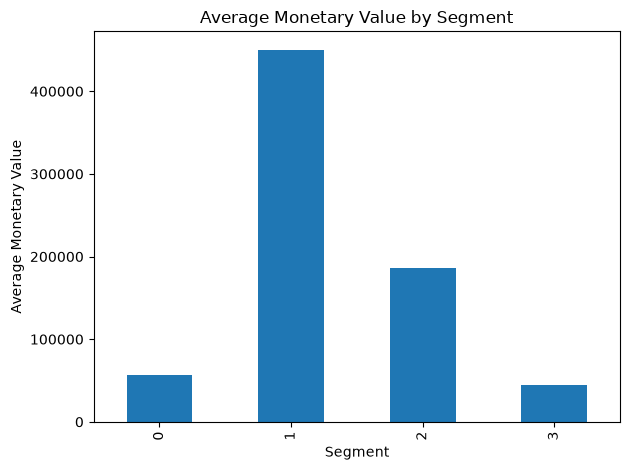

In [4]:
import matplotlib.pyplot as plt

rfm.groupby("Segment")["Monetary"].mean().plot(kind="bar")
plt.title("Average Monetary Value by Segment")
plt.xlabel("Segment")
plt.ylabel("Average Monetary Value")
plt.tight_layout()
plt.show()

In [5]:
rfm.to_csv(data_path / "customer_segments.csv")
print("Segmentation analysis completed and saved.")

Segmentation analysis completed and saved.


In [6]:
labels = {
    0: "Inactive Customers",
    1: "High Value Customers",
    2: "Recent Regular Customers",
    3: "Recent Low Frequency Customers"
}

rfm["Segment_Label"] = rfm["Segment"].map(labels)

rfm[["Segment", "Segment_Label"]].head()

,Segment,Segment_Label
customer_id,,
CUST100000,0,Inactive Customers
CUST100001,1,High Value Customers
CUST100002,2,Recent Regular Customers
CUST100003,3,Recent Low Frequency Customers
CUST100004,0,Inactive Customers


In [7]:
rfm.to_csv(data_path / "customer_segments.csv")
print("Final segment labels saved!")

Final segment labels saved!
